# Week 2 — Spiking simulation and sanity checks

Uses the weight set from `02_weights.ipynb` and the LIF module `sim/lif.py` (Shiu et al. 2024 parameters, copied from their `model.py`).

Checks, in order (each must pass before the next):
1. **Direct targets:** stimulate JO-C/E; their direct postsynaptic partners should fire.
2. **Known benchmark:** sugar GRNs (LB3b/LB3c) → proboscis motor neuron MN9
3. JO-C/E → descending candidates → front-leg motor neurons *(next)*
4. Shuffled control *(next)*

Memory: WSL is capped at 4 GB, so the checks run on subnetworks. Each build prints peak memory.

### Setup

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

BRAIN = Path.home() / 'arm_simulation/brain'     # on Colab, change only these two lines
DATA = BRAIN / 'data'
sys.path.insert(0, str(BRAIN))

from sim.lif import WeightSet, LIFNet, SHIU, peak_mem_gb
from brian2 import Hz, second, prefs

ws = WeightSet(DATA / 'weights_male-cns_v1.0')
print(f"{ws.N:,} neurons, {len(ws.count):,} edges, guessed neurons: {ws.meta['guessed_neurons']:,}")
from brian2.codegen.runtime.cython_rt import CythonCodeObject
print(f"Brian2 fast C code (Cython) available: {CythonCodeObject.is_available()}")
print(f"peak memory: {peak_mem_gb():.2f} GB")

176,422 neurons, 25,862,574 edges, guessed neurons: 25,159
Brian2 fast C code (Cython) available: True
peak memory: 1.12 GB


### Cell 1: check the histamine fill

Step 2 filled 5,854 unclear neurons as histamine. That's fine if they are photoreceptor types; if non-photoreceptor types show up here, tell me.

In [2]:
h = ws.neurons[ws.neurons.guessed & (ws.neurons.nt_used == 'histamine')]
print(f"guessed as histamine: {len(h):,}")
display(h['cls'].value_counts().to_frame('neurons'))
display(h['type'].value_counts().head(15).to_frame('neurons'))

guessed as histamine: 5,789


,neurons
cls,
ol_sensory,3960
ol_intrinsic,1829


,neurons
type,
R1-R6,2627
T1,1776
R7y,416
R7_unclear,329
R7p,254
R8_unclear,156
R8y,91
Lai,53
R8p,53


### Cell 2: neuron groups

JO-C/E and the Week 1 shortlist, plus a search for the check 2 neurons (sugar GRNs and MN9). Send me the search output; the exact male-CNS type names decide check 2.

In [3]:
JO = ws.by_type(r'^JO-(C|E)', cls='cb_sensory')
print(f"JO-C/E: {len(JO)} neurons (Week 1: 335)")

shortlist = pd.read_csv(DATA / 'shortlist_week1.csv')
g2i = pd.Series(ws.neurons.index, index=ws.neurons.bodyId)
DN_cand = g2i.loc[shortlist.query("group == 'middle_descending'").bodyId].to_numpy()
LEG_MN  = g2i.loc[shortlist.query("group == 'output_T1_leg_MN'").bodyId].to_numpy()
print(f"descending candidates: {len(DN_cand)}  front-leg motor neurons: {len(LEG_MN)}")

types = ws.neurons['type'].astype(str)
sens = ws.neurons[(ws.neurons.cls == 'cb_sensory') &
                  types.str.contains(r'(?i)gr5|gr64|sugar|sweet|gust|GRN|taste|pharyn|labell')]
print(f"\ngustatory-looking sensory neurons: {len(sens)}")
display(sens['type'].value_counts().head(30).to_frame('neurons'))

mn = ws.neurons[types.str.contains(r'(?i)^MN9|mn9|proboscis')]
print(f"MN9-looking neurons: {len(mn)}")
display(mn[['bodyId', 'type', 'cls', 'nt_used']])

JO-C/E: 335 neurons (Week 1: 335)
descending candidates: 68  front-leg motor neurons: 81

gustatory-looking sensory neurons: 100


,neurons
type,
claw_tpGRN,50
BM_Taste,40
dorsal_tpGRN,10


MN9-looking neurons: 2


,bodyId,type,cls,nt_used
13273,10331,MN9,cb_motor,acetylcholine
13385,16949,MN9,cb_motor,acetylcholine


### Cell 3: check 1, direct targets

Subnetwork = JO-C/E plus every neuron they synapse onto directly. Stimulate JO-C/E at 150 Hz for 1 s (5 trials), plus a no-stimulus baseline.

**Pass:** baseline is silent (the model has no spontaneous firing), JO-C/E fire near 150 Hz, and targets with many synapses from JO-C/E fire. If strongly connected targets stay silent, it's a bug, not biology.

In [4]:
tgt = ws.partners(JO, 'out', min_syn=1).drop(JO, errors='ignore')
print(f"direct targets of JO-C/E: {len(tgt):,}")

sub1 = ws.subnetwork(np.concatenate([JO, tgt.index]))
net1 = LIFNet(sub1, stim_global=JO)

spk0 = net1.run(rate=0 * Hz, n_trials=2)
print(f"baseline spikes: {len(spk0)} (should be 0)\n")

spk1 = net1.run(n_trials=5)
r1 = net1.rates(spk1, ws)
r1['syn_from_JO'] = tgt.reindex(r1.index)

t1 = r1.loc[tgt.index]
print(f"\nJO-C/E mean rate: {r1.loc[JO, 'rate_hz'].mean():.0f} Hz (stimulus 150 Hz)")
for k in [1, 5, 10, 20, 50]:
    s = t1[t1.syn_from_JO >= k]
    print(f"targets with >= {k:2d} synapses from JO: {len(s):5,}, firing >= 1 Hz: {(s.rate_hz >= 1).mean():6.1%}")
print(f"rank correlation, synapses from JO vs rate: {t1.syn_from_JO.corr(t1.rate_hz, method='spearman'):.2f}")
display(t1.sort_values('syn_from_JO', ascending=False).head(20))

direct targets of JO-C/E: 2,087
built: 2,422 neurons, 220,173 connections, 0.1 s, peak memory 1.60 GB
2 trials × 1 s: 1.3 s, peak memory 1.60 GB
baseline spikes: 0 (should be 0)

5 trials × 1 s: 2.6 s, peak memory 1.60 GB

JO-C/E mean rate: 147 Hz (stimulus 150 Hz)
targets with >=  1 synapses from JO: 2,087, firing >= 1 Hz:  43.0%
targets with >=  5 synapses from JO: 1,474, firing >= 1 Hz:  54.6%
targets with >= 10 synapses from JO: 1,262, firing >= 1 Hz:  60.5%
targets with >= 20 synapses from JO: 1,040, firing >= 1 Hz:  67.9%
targets with >= 50 synapses from JO:   714, firing >= 1 Hz:  80.7%
rank correlation, synapses from JO vs rate: 0.63


,bodyId,type,cls,nt_used,rate_hz,syn_from_JO
157498,11960,AMMC012,cb_intrinsic,acetylcholine,198.2,2037.0
74544,10446,DNp73,descending_neuron,acetylcholine,156.8,1682.0
94626,523640,AMMC013,cb_intrinsic,acetylcholine,167.2,1614.0
40680,10371,WED203,cb_intrinsic,gaba,11.8,1457.0
52314,10536,DNg29,descending_neuron,acetylcholine,165.0,1435.0
137612,524470,DNbe001,descending_neuron,acetylcholine,178.8,1311.0
151286,10048,DNp18,descending_neuron,acetylcholine,190.8,1236.0
44587,15952,SAD004,cb_intrinsic,acetylcholine,161.4,1142.0
47429,13306,AMMC038,cb_intrinsic,gaba,171.2,1100.0
107703,11702,AMMC012,cb_intrinsic,acetylcholine,165.2,1098.0


### Cell 4: raster and rate vs connection strength

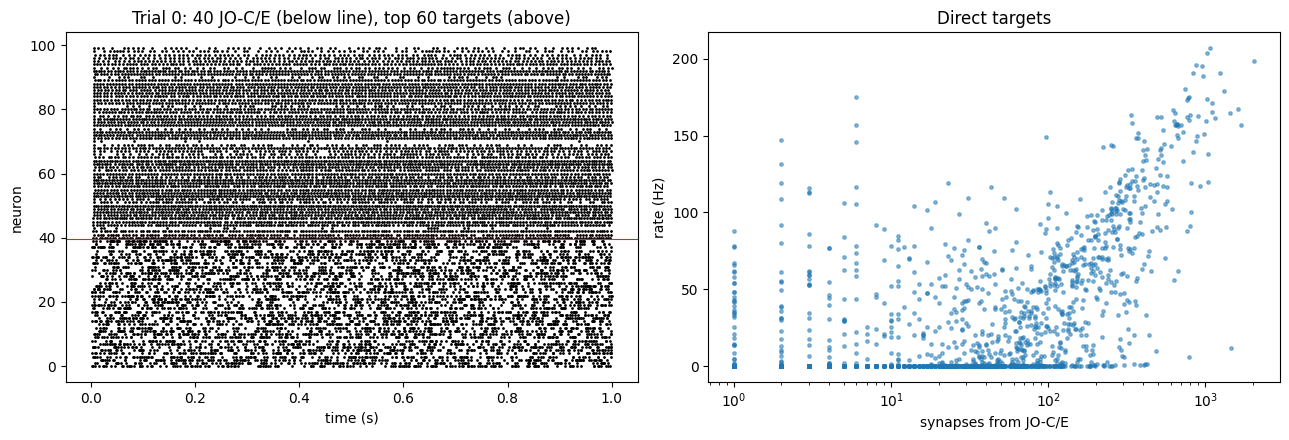

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

show = np.concatenate([JO[:40], t1.sort_values('syn_from_JO', ascending=False).index[:60]])
local = pd.Series(np.arange(len(net1.keep)), index=net1.keep).loc[show].to_numpy()
row = {l: r for r, l in enumerate(local)}
s = spk1[(spk1.trial == 0) & spk1.local.isin(local)]
ax[0].scatter(s.t, s.local.map(row), s=1, c='k')
ax[0].axhline(39.5, color='tab:red', lw=0.8)
ax[0].set(xlabel='time (s)', ylabel='neuron', title='Trial 0: 40 JO-C/E (below line), top 60 targets (above)')

ax[1].scatter(t1.syn_from_JO, t1.rate_hz, s=6, alpha=0.5)
ax[1].set(xscale='log', xlabel='synapses from JO-C/E', ylabel='rate (Hz)', title='Direct targets')
plt.tight_layout()
plt.savefig(DATA / 'check1_direct_targets.png', dpi=120)

---
### Cell 5: check 2 groups, sugar GRNs and MN9

In male-CNS, labellar taste neurons are typed by anatomy (LB…), not by taste. Tastekin, de Haan Vicente et al. 2026 assign **LB3b and LB3c** as sugar-sensing. MN9 is the pair 10331 (L) and 16949 (R), found in Cell 2.

In [6]:
types = ws.neurons['type'].astype(str)
lb = ws.neurons[(ws.neurons.cls == 'cb_sensory') & types.str.match(r'^LB')]
print("labellar (LB) sensory types:")
display(lb['type'].value_counts().sort_index().to_frame('neurons').T)

SUGAR = ws.by_type(r'^LB3(b|c)$', cls='cb_sensory')
MN9 = ws.by_type(r'^MN9$')
assert len(SUGAR) > 0, "no LB3b/LB3c found: send me the LB type list above"
print(f"sugar GRNs: {len(SUGAR)}")
display(ws.neurons.loc[SUGAR].groupby(['type', 'side'], dropna=False).size().to_frame('neurons'))
display(ws.neurons.loc[MN9, ['bodyId', 'type', 'side', 'nt_used']])

labellar (LB) sensory types:


type,LB1a,LB1b,LB1c,LB1d,LB1e,LB2a,LB2b,LB2c,LB2d,LB3,LB3a,LB3b,LB3c,LB3d,LB4a,LB4b
neurons,11,6,16,5,19,4,3,6,5,1,17,11,23,26,4,8


sugar GRNs: 34


,,neurons
type,side,
LB3b,NaN,11
LB3c,NaN,23


,bodyId,type,side,nt_used
13273,10331,MN9,L,acetylcholine
13385,16949,MN9,R,acetylcholine


### Cell 6: check 2 subnetwork

The full network doesn't fit in 4 GB, so this keeps neurons that lie on **short paths** from sugar GRNs to MN9: a neuron is kept if (hops from sugar) + (hops to MN9) ≤ L. The search counts only connections with ≥5 synapses; all connections among the kept neurons are simulated.

The cell starts at the shortest sugar → MN9 path length and adds one hop at a time while the subnetwork stays under ~2.5M connections.

Caveat: neurons off these paths are missing, including some inhibition, so MN9 may respond more strongly here than in the full network. The chosen `w_syn` gets confirmed on the full network on Colab later.

In [7]:
MAX_CONN = 2_500_000

on_path, d_fwd, d_bwd = ws.path_neurons(SUGAR, MN9, max_len=6, min_syn=5)
shortest = int(d_fwd[MN9][d_fwd[MN9] >= 0].min())
print(f"\nshortest sugar -> MN9 path: {shortest} hops "
      f"(MN9 L: {d_fwd[MN9[0]]}, R: {d_fwd[MN9[1]]})\n")

total = d_fwd.astype(int) + d_bwd
ok = (d_fwd >= 0) & (d_bwd >= 0)
sizes = []
for L in range(shortest, 7):
    k = np.union1d(np.flatnonzero(ok & (total <= L)), np.concatenate([SUGAR, MN9]))
    n_conn = len(ws.subnetwork(k)['w'])
    sizes.append((L, len(k), n_conn))
    print(f"L = {L}: {len(k):>7,} neurons, {n_conn:>10,} connections")
    if n_conn > MAX_CONN:
        break

L2, _, _ = [s_ for s_ in sizes if s_[2] <= MAX_CONN][-1]
keep2 = np.union1d(np.flatnonzero(ok & (total <= L2)), np.concatenate([SUGAR, MN9]))
sub2 = ws.subnetwork(keep2)
print(f"\nusing L = {L2}: {len(keep2):,} neurons, {len(sub2['w']):,} connections")
display(ws.neurons.loc[keep2, 'cls'].value_counts().head(10).to_frame('neurons'))

downstream of source:
  hop 1: +142 new, 176 total
  hop 2: +4,863 new, 5,039 total
  hop 3: +48,630 new, 53,669 total
  hop 4: +88,096 new, 141,765 total
  hop 5: +20,868 new, 162,633 total
  hop 6: +2,885 new, 165,518 total
upstream of target:
  hop 1: +98 new, 100 total
  hop 2: +3,336 new, 3,436 total
  hop 3: +40,806 new, 44,242 total
  hop 4: +95,476 new, 139,718 total
  hop 5: +25,048 new, 164,766 total
  hop 6: +2,788 new, 167,554 total

shortest sugar -> MN9 path: 2 hops (MN9 L: 2, R: 3)

L = 2:      40 neurons,        358 connections
L = 3:     212 neurons,      8,738 connections
L = 4:   1,414 neurons,    159,022 connections
L = 5:   6,004 neurons,    818,603 connections
L = 6:  30,838 neurons,  5,818,013 connections

using L = 5: 6,004 neurons, 818,603 connections


,neurons
cls,
cb_intrinsic,2448
vnc_intrinsic,1189
ascending_neuron,798
cb_sensory,794
descending_neuron,559
cb_motor,48
vnc_sensory,39
sensory_ascending,34
visual_projection,21


### Cell 7: check 2 simulation

Stimulate all LB3b/LB3c at 150 Hz (Shiu's default) and 50 Hz, 5 trials each, plus a no-stimulus baseline.

**Pass:** baseline silent, and MN9 fires under sugar stimulation. If MN9 is silent, that alone doesn't mean a bug: `w_syn` was tuned on FlyWire and may be too weak here, which the Step 5 sweep tests. A bug is if neurons one step downstream of sugar are silent too.

In [8]:
net2 = LIFNet(sub2, stim_global=SUGAR)
spk = net2.run(rate=0 * Hz, n_trials=1)
print(f"baseline spikes: {len(spk)} (should be 0)\n")

res2 = {}
for rate in [50, 150]:
    spk = net2.run(rate=rate * Hz, n_trials=5)
    r = net2.rates(spk, ws)
    res2[rate] = r
    print(f"  sugar GRN rate {r.loc[SUGAR, 'rate_hz'].mean():.0f} Hz | "
          f"MN9: " + ', '.join(f"{ws.neurons.side[i]} {r.rate_hz[i]:.1f} Hz" for i in MN9) +
          f" | subnetwork neurons firing: {(r.drop(SUGAR).rate_hz >= 1).mean():.1%}\n")

direct = ws.partners(SUGAR, 'out', min_syn=5).drop(SUGAR, errors='ignore')
direct = direct[direct.index.isin(keep2)]
r = res2[150]
print(f"direct sugar targets (>=5 syn) in subnetwork: {len(direct)}, firing >= 1 Hz: {(r.loc[direct.index, 'rate_hz'] >= 1).mean():.0%}")
print("\nmost active neurons at 150 Hz (excluding sugar GRNs):")
display(r.drop(SUGAR).sort_values('rate_hz', ascending=False).head(20))

built: 6,004 neurons, 818,603 connections, 0.1 s, peak memory 1.78 GB
1 trials × 1 s: 0.6 s, peak memory 1.78 GB
baseline spikes: 0 (should be 0)

5 trials × 1 s: 3.0 s, peak memory 1.78 GB
  sugar GRN rate 49 Hz | MN9: L 41.8 Hz, R 1.8 Hz | subnetwork neurons firing: 9.8%

5 trials × 1 s: 3.0 s, peak memory 1.78 GB
  sugar GRN rate 148 Hz | MN9: L 96.4 Hz, R 15.2 Hz | subnetwork neurons firing: 12.1%

direct sugar targets (>=5 syn) in subnetwork: 209, firing >= 1 Hz: 49%

most active neurons at 150 Hz (excluding sugar GRNs):


,bodyId,type,cls,nt_used,rate_hz
13287,11393,MN11D,cb_motor,acetylcholine,178.2
13284,11269,MN11D,cb_motor,acetylcholine,168.0
46817,512550,GNG038,cb_intrinsic,gaba,165.8
13419,21746,GNG038,cb_intrinsic,gaba,157.4
169440,10205,GNG003,cb_intrinsic,gaba,154.8
13203,533971,MNx01,cb_motor,glutamate,150.0
13472,43293,GNG041,cb_intrinsic,gaba,141.2
13353,15321,GNG042,cb_intrinsic,gaba,135.2
21916,16630,GNG479,cb_intrinsic,gaba,135.2
21904,15734,GNG042,cb_intrinsic,gaba,134.0
